Phone Battery Drain Prediction Using Machine Learning

Project Overview

Smartphone battery consumption depends on several factors such as screen time, application usage, mobile data usage, number of installed applications, device model, and operating system.

In this project, Machine Learning regression techniques are used to predict the daily battery consumption of a smartphone.

The target variable is **Battery Drain (mAh/day)**.

Points : 

- Understand smartphone usage data.
- Analyze factors affecting battery consumption.
- Perform data cleaning and exploratory data analysis.
- Train different regression models.
- Evaluate and compare model performance.
- Predict battery consumption for new smartphone usage data.

Importing Libraries

In [20]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

Loading Dataset

In [22]:
data = pd.read_csv(
    r"C:\Users\Akshaya\OneDrive\Desktop\ML_Regression\user_behavior_dataset.csv"
)

Data Understanding

1. shape : for how many columns and rows will be there in the dataset

In [3]:
data.shape

(700, 11)

2. head() : showcasing the first five rows of the dataset

In [4]:
data.head()

,User ID,Device Model,Operating System,App Usage Time (min/day),Screen On Time (hours/day),Battery Drain (mAh/day),Number of Apps Installed,Data Usage (MB/day),Age,Gender,User Behavior Class
0,1,Google Pixel 5,Android,393,6.4,1872,67,1122,40,Male,4
1,2,OnePlus 9,Android,268,4.7,1331,42,944,47,Female,3
2,3,Xiaomi Mi 11,Android,154,4.0,761,32,322,42,Male,2
3,4,Google Pixel 5,Android,239,4.8,1676,56,871,20,Male,3
4,5,iPhone 12,iOS,187,4.3,1367,58,988,31,Female,3


3. tail() : showcasing the last five rows of the dataset

In [5]:
data.tail()

,User ID,Device Model,Operating System,App Usage Time (min/day),Screen On Time (hours/day),Battery Drain (mAh/day),Number of Apps Installed,Data Usage (MB/day),Age,Gender,User Behavior Class
695,696,iPhone 12,iOS,92,3.9,1082,26,381,22,Male,2
696,697,Xiaomi Mi 11,Android,316,6.8,1965,68,1201,59,Male,4
697,698,Google Pixel 5,Android,99,3.1,942,22,457,50,Female,2
698,699,Samsung Galaxy S21,Android,62,1.7,431,13,224,44,Male,1
699,700,OnePlus 9,Android,212,5.4,1306,49,828,23,Female,3


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   User ID                     700 non-null    int64  
 1   Device Model                700 non-null    object 
 2   Operating System            700 non-null    object 
 3   App Usage Time (min/day)    700 non-null    int64  
 4   Screen On Time (hours/day)  700 non-null    float64
 5   Battery Drain (mAh/day)     700 non-null    int64  
 6   Number of Apps Installed    700 non-null    int64  
 7   Data Usage (MB/day)         700 non-null    int64  
 8   Age                         700 non-null    int64  
 9   Gender                      700 non-null    object 
 10  User Behavior Class         700 non-null    int64  
dtypes: float64(1), int64(7), object(3)
memory usage: 60.3+ KB


In [7]:
data.columns

Index(['User ID', 'Device Model', 'Operating System',
       'App Usage Time (min/day)', 'Screen On Time (hours/day)',
       'Battery Drain (mAh/day)', 'Number of Apps Installed',
       'Data Usage (MB/day)', 'Age', 'Gender', 'User Behavior Class'],
      dtype='object')

In [8]:
data.describe()

,User ID,App Usage Time (min/day),Screen On Time (hours/day),Battery Drain (mAh/day),Number of Apps Installed,Data Usage (MB/day),Age,User Behavior Class
count,700.00000,700.000000,700.000000,700.000000,700.000000,700.000000,700.000000,700.000000
mean,350.50000,271.128571,5.272714,1525.158571,50.681429,929.742857,38.482857,2.990000
std,202.21688,177.199484,3.068584,819.136414,26.943324,640.451729,12.012916,1.401476
min,1.00000,30.000000,1.000000,302.000000,10.000000,102.000000,18.000000,1.000000
25%,175.75000,113.250000,2.500000,722.250000,26.000000,373.000000,28.000000,2.000000
50%,350.50000,227.500000,4.900000,1502.500000,49.000000,823.500000,38.000000,3.000000
75%,525.25000,434.250000,7.400000,2229.500000,74.000000,1341.000000,49.000000,4.000000
max,700.00000,598.000000,12.000000,2993.000000,99.000000,2497.000000,59.000000,5.000000


Data Preprocessing

In [9]:
data.isnull().sum()

User ID                       0
Device Model                  0
Operating System              0
App Usage Time (min/day)      0
Screen On Time (hours/day)    0
Battery Drain (mAh/day)       0
Number of Apps Installed      0
Data Usage (MB/day)           0
Age                           0
Gender                        0
User Behavior Class           0
dtype: int64

In [10]:
data.duplicated().sum()

np.int64(0)

In [11]:
data.drop_duplicates()

,User ID,Device Model,Operating System,App Usage Time (min/day),Screen On Time (hours/day),Battery Drain (mAh/day),Number of Apps Installed,Data Usage (MB/day),Age,Gender,User Behavior Class
0,1,Google Pixel 5,Android,393,6.4,1872,67,1122,40,Male,4
1,2,OnePlus 9,Android,268,4.7,1331,42,944,47,Female,3
2,3,Xiaomi Mi 11,Android,154,4.0,761,32,322,42,Male,2
3,4,Google Pixel 5,Android,239,4.8,1676,56,871,20,Male,3
4,5,iPhone 12,iOS,187,4.3,1367,58,988,31,Female,3
...,...,...,...,...,...,...,...,...,...,...,...
695,696,iPhone 12,iOS,92,3.9,1082,26,381,22,Male,2
696,697,Xiaomi Mi 11,Android,316,6.8,1965,68,1201,59,Male,4
697,698,Google Pixel 5,Android,99,3.1,942,22,457,50,Female,2
698,699,Samsung Galaxy S21,Android,62,1.7,431,13,224,44,Male,1


EDA (Exploratory Data Analysis)

1. Battery drain distribution

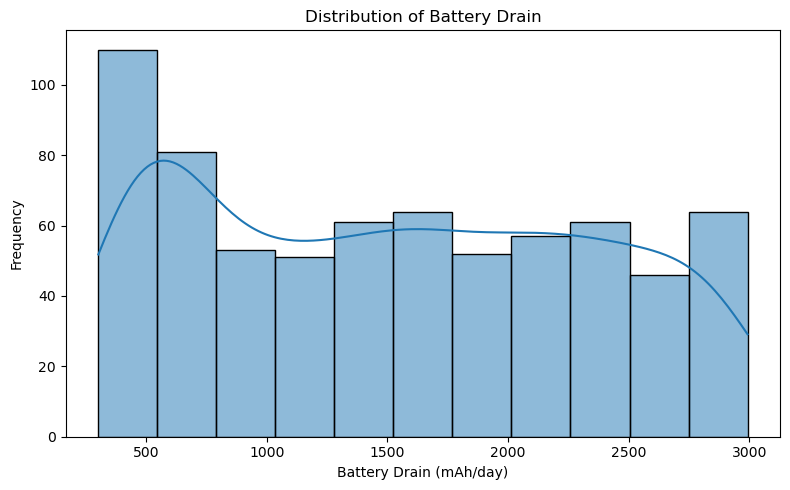

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data["Battery Drain (mAh/day)"],
    kde=True
)

plt.title("Distribution of Battery Drain")
plt.xlabel("Battery Drain (mAh/day)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

2.Screen time vs Battery Drain

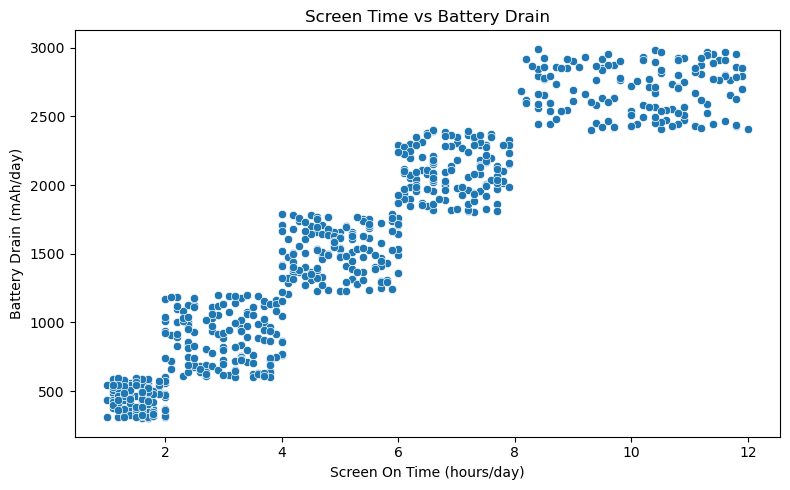

In [24]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="Screen On Time (hours/day)",
    y="Battery Drain (mAh/day)"
)

plt.title("Screen Time vs Battery Drain")
plt.xlabel("Screen On Time (hours/day)")
plt.ylabel("Battery Drain (mAh/day)")

plt.tight_layout()
plt.show()

3. App usage vs Battery Drain

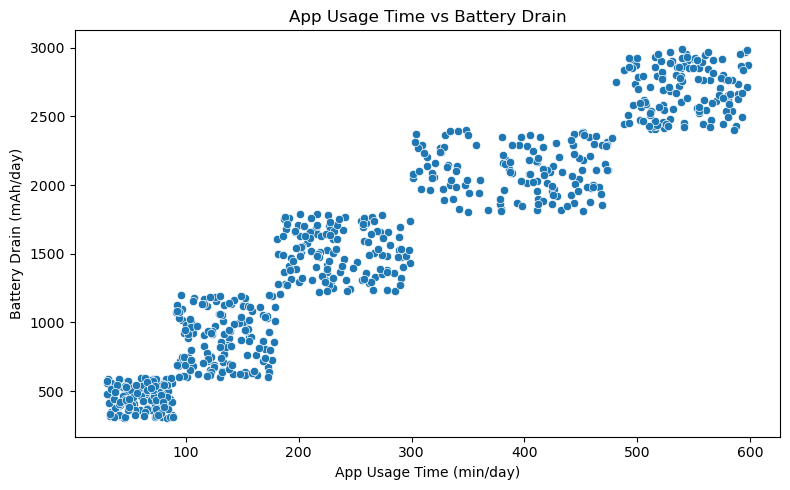

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="App Usage Time (min/day)",
    y="Battery Drain (mAh/day)"
)

plt.title("App Usage Time vs Battery Drain")
plt.xlabel("App Usage Time (min/day)")
plt.ylabel("Battery Drain (mAh/day)")

plt.tight_layout()
plt.show()


4. Data Usage vs Battery drain

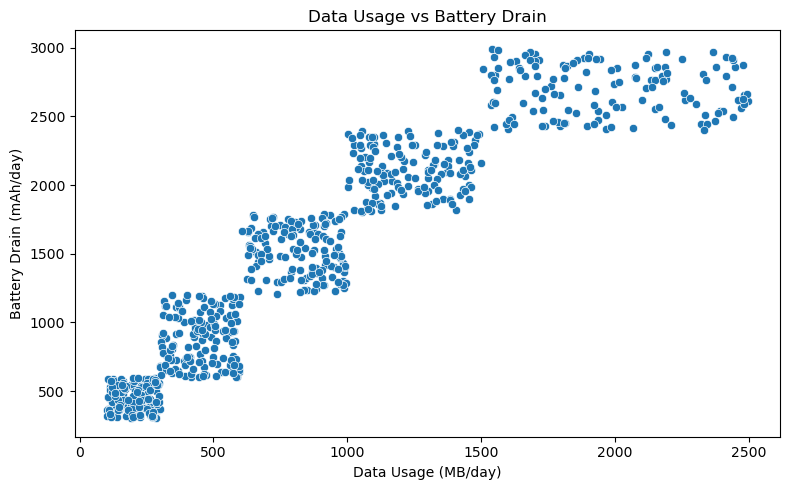

In [27]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="Data Usage (MB/day)",
    y="Battery Drain (mAh/day)"
)

plt.title("Data Usage vs Battery Drain")
plt.xlabel("Data Usage (MB/day)")
plt.ylabel("Battery Drain (mAh/day)")

plt.tight_layout()
plt.show()

Feature Engineering

In [13]:


data["Screen Time (min/day)"] = (
    data["Screen On Time (hours/day)"] * 60
)

# Calculate average data usage per hour of screen time
data["Data Usage per Screen Hour"] = (
    data["Data Usage (MB/day)"] /
    (data["Screen On Time (hours/day)"] + 0.1)
)

# Calculate app usage per installed application
data["App Usage per Installed App"] = (
    data["App Usage Time (min/day)"] /
    (data["Number of Apps Installed"] + 1)
)

print("Feature engineering completed!")

data.head()

Feature engineering completed!


,User ID,Device Model,Operating System,App Usage Time (min/day),Screen On Time (hours/day),Battery Drain (mAh/day),Number of Apps Installed,Data Usage (MB/day),Age,Gender,User Behavior Class,Screen Time (min/day),Data Usage per Screen Hour,App Usage per Installed App
0,1,Google Pixel 5,Android,393,6.4,1872,67,1122,40,Male,4,384.0,172.615385,5.779412
1,2,OnePlus 9,Android,268,4.7,1331,42,944,47,Female,3,282.0,196.666667,6.232558
2,3,Xiaomi Mi 11,Android,154,4.0,761,32,322,42,Male,2,240.0,78.536585,4.666667
3,4,Google Pixel 5,Android,239,4.8,1676,56,871,20,Male,3,288.0,177.755102,4.192982
4,5,iPhone 12,iOS,187,4.3,1367,58,988,31,Female,3,258.0,224.545455,3.169492


In [45]:
# Feature Engineering

# 1. Convert screen time from hours to minutes
data["Screen Time (min/day)"] = (
    data["Screen On Time (hours/day)"] * 60
)

# 2. Calculate data usage per screen hour
data["Data Usage per Screen Hour"] = (
    data["Data Usage (MB/day)"] /
    (data["Screen On Time (hours/day)"] + 0.1)
)

# 3. Calculate app usage per installed application
data["App Usage per Installed App"] = (
    data["App Usage Time (min/day)"] /
    (data["Number of Apps Installed"] + 1)
)

print("Feature Engineering Completed!")

print("\nNew Features:")
print("1. Screen Time (min/day)")
print("2. Data Usage per Screen Hour")
print("3. App Usage per Installed App")

Feature Engineering Completed!

New Features:
1. Screen Time (min/day)
2. Data Usage per Screen Hour
3. App Usage per Installed App


Feature selection

In [46]:
# Feature Selection

features = [
    "App Usage Time (min/day)",
    "Screen On Time (hours/day)",
    "Number of Apps Installed",
    "Data Usage (MB/day)",
    "Age",
    "Screen Time (min/day)",
    "Data Usage per Screen Hour",
    "App Usage per Installed App",
    "Device Model",
    "Operating System",
    "Gender"
]

target = "Battery Drain (mAh/day)"

X = data[features]
y = data[target]

print("Selected Features:")

for feature in features:
    print("-", feature)

print("\nTarget Variable:")
print("-", target)

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Selected Features:
- App Usage Time (min/day)
- Screen On Time (hours/day)
- Number of Apps Installed
- Data Usage (MB/day)
- Age
- Screen Time (min/day)
- Data Usage per Screen Hour
- App Usage per Installed App
- Device Model
- Operating System
- Gender

Target Variable:
- Battery Drain (mAh/day)

X Shape: (700, 11)
y Shape: (700,)


Testing and Training the data

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (560, 11)
Testing data shape: (140, 11)


Feature Scaling

In [33]:
numerical_features = [
    "App Usage Time (min/day)",
    "Screen On Time (hours/day)",
    "Number of Apps Installed",
    "Data Usage (MB/day)",
    "Age",
    "Screen Time (min/day)",
    "Data Usage per Screen Hour",
    "App Usage per Installed App"
]

categorical_features = [
    "Device Model",
    "Operating System",
    "Gender"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

print("Feature scaling and encoding setup completed!")

Feature scaling and encoding setup completed!


Model Selection

In [34]:
# Model Selection

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest Regression": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

print("Selected Models:")
for name in models:
    print("-", name)

Selected Models:
- Linear Regression
- Random Forest Regression


Model Training

In [35]:
# Model Training

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

Linear Regression trained successfully!
Random Forest Regression trained successfully!


Model Evaluation

Model Evaluation Results:


,Model,MAE,RMSE,R² Score
0,Linear Regression,157.240064,185.289344,0.944676
1,Random Forest Regression,146.352071,172.859189,0.951850


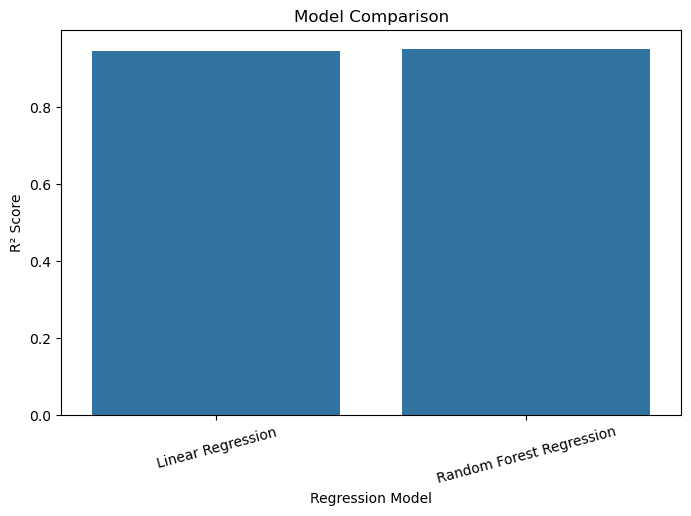

In [36]:
# Model Evaluation

results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R² Score": r2
    })


results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df)


# Visual comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R² Score"
)

plt.title("Model Comparison")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")

plt.xticks(rotation=15)

plt.show()

Model Evaluation and Model Comparision

Model Evaluation Results:


,Model,MAE,RMSE,R² Score
0,Linear Regression,157.240064,185.289344,0.944676
1,Random Forest Regression,146.352071,172.859189,0.951850


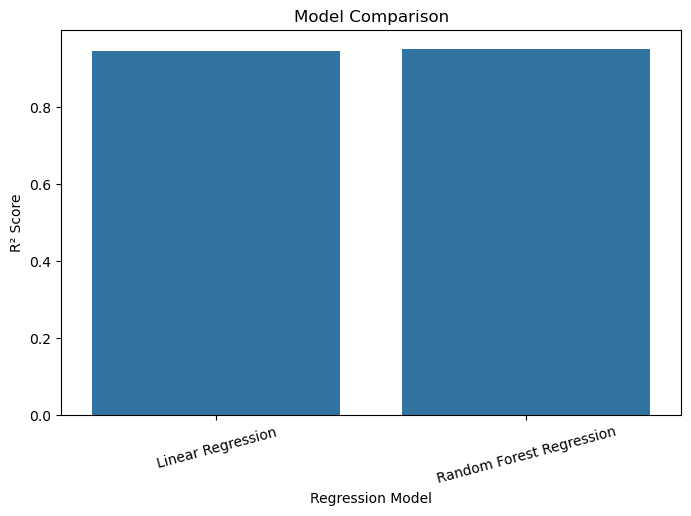

In [37]:
# Model Evaluation

results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R² Score": r2
    })


results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df)


# Visual comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R² Score"
)

plt.title("Model Comparison")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")

plt.xticks(rotation=15)

plt.show()

Model Saving

In [40]:
best_model_name = results_df.loc[
    results_df["R² Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
joblib.dump(
    best_model,
    "battery_drain_prediction_model.pkl"
)

print("Best model saved successfully!")

Best Model: Random Forest Regression
Best model saved successfully!


In [41]:
loaded_model = joblib.load(
    "battery_drain_prediction_model.pkl"
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [42]:
new_data = pd.DataFrame({
    "App Usage Time (min/day)": [300],
    "Screen On Time (hours/day)": [5],
    "Number of Apps Installed": [50],
    "Data Usage (MB/day)": [1500],
    "Age": [21],
    "Screen Time (min/day)": [300],
    "Data Usage per Screen Hour": [1500 / (5 + 0.1)],
    "App Usage per Installed App": [300 / (50 + 1)],
    "Device Model": ["Samsung Galaxy S21"],
    "Operating System": ["Android"],
    "Gender": ["Female"]
})

In [43]:
predicted_battery_drain = loaded_model.predict(new_data)

print(
    "Predicted Battery Drain:",
    predicted_battery_drain[0],
    "mAh/day"
)

Predicted Battery Drain: 1745.31 mAh/day
